# Test-time solver vs. test-time training: what does the memory give back?

This notebook needs **no weights and no data** (it runs on a GPU if one is available, otherwise on the CPU). It isolates the one operation that differs between our
**Test-Time Solver (TTS)** and **test-time training (TTT)** as used by LaCT / FSM: how the key-value pairs of the input
tokens are *written* into a fast weight.

* **TTT (FSM-style)** — tokens arrive in chunks; each chunk gets **one** optimization step on the fast weight
  (we use the dot-product loss of LaCT/FSM, a Muon-orthogonalized update and a renormalization, as in FSM).
* **TTS (ours)** — all tokens are written at once by solving the ridge regression
  $\min_W \sum_n a_n\|W\tilde\psi_n-\tilde v_n\|^2+\lambda\|W-W^{\mathrm{init}}\|_F^2$ in closed form,
  $W^\star=(\tilde C+\lambda W^{\mathrm{init}})(\tilde G+\lambda I)^{-1}$.

We then **read the written keys back** and measure how much of each value the memory returns. Real keys are far from
orthogonal (in our trained model the mean $\cos^2$ between feature vectors is about 0.57, versus $1/h$ for random ones), so
we generate keys that share a common direction with that level of correlation.

This is a simplified, self-contained re-implementation for illustration: the numbers are not those of the paper, but the
behaviour is the same.

In [1]:
import math, time
import numpy as np
import torch
import matplotlib.pyplot as plt
torch.manual_seed(0)
dev = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", dev)

h, d = 256, 128            # feature (key) dimension, value dimension
TOK_PER_VIEW = 256         # 128x128 image, 8x8 patches
CHUNK = 2048               # TTT chunk size (tokens per optimization step)
VIEWS = [4, 8, 16, 32, 64, 128]

D_TOK = 64                 # token dimension
_g = torch.Generator().manual_seed(123)
A = torch.randn(h, D_TOK, generator=_g) / math.sqrt(D_TOK)    # key projections (W1, W3 of the SwiGLU feature map)
B = torch.randn(h, D_TOK, generator=_g) / math.sqrt(D_TOK)
Wv = torch.randn(d, D_TOK, generator=_g) / math.sqrt(D_TOK)   # value projection
U_SHARED = torch.randn(D_TOK, generator=_g); U_SHARED /= U_SHARED.norm()

def make_tokens(M, shared=2.6, seed=0):
    # Tokens x share a common direction (as image tokens of one scene do); keys are the unit-norm SwiGLU features
    # psi(x) = phi(x)/||phi(x)||, phi(x) = SiLU(A x) * (B x), values are v = Wv x -- both are projections of the same token.
    g = torch.Generator().manual_seed(seed)
    x = torch.randn(M, D_TOK, generator=g) + shared * math.sqrt(D_TOK) * U_SHARED
    phi = torch.nn.functional.silu(x @ A.T) * (x @ B.T)
    k = phi / phi.norm(dim=1, keepdim=True)
    v = x @ Wv.T
    return k.to(dev), v.to(dev)

k, v = make_tokens(4096)
c = (k @ k.T)
print("mean cos^2 between different keys: %.2f   (random keys: %.4f)" % ((c**2).sum().sub(len(k)).div(len(k)*(len(k)-1)).item(), 1/h))

device: cuda


mean cos^2 between different keys: 0.54   (random keys: 0.0039)


## The two writes

`ttt_write` follows FSM: for every chunk, the gradient of the dot-product loss $L_c=-\sum_{n\in c} v_n^\top W k_n$ with
respect to $W$ is $-\sum_{n\in c} v_n k_n^\top$; Muon orthogonalizes it with 5 Newton–Schulz iterations, and Norm restores
the row norms of the weight. `tts_write` is our closed-form ridge solve on centred and rescaled features; the read adds the
mean value back.

In [2]:
def newton_schulz(G, steps=5):
    # Muon's orthogonalization (quintic Newton-Schulz), as in FSM/LaCT.
    a, b, c = 3.4445, -4.7750, 2.0315
    X = G / (G.norm() + 1e-7)
    tr = X.shape[0] > X.shape[1]
    if tr: X = X.T
    for _ in range(steps):
        A = X @ X.T
        X = a * X + (b * A + c * A @ A) @ X
    return X.T if tr else X

def ttt_write(k, v, W0, lr=1.0, chunk=CHUNK):
    W = W0.to(k.device).clone(); row_norm = W.norm(dim=1, keepdim=True)
    for s in range(0, len(k), chunk):
        kc, vc = k[s:s+chunk], v[s:s+chunk]
        grad = -(vc.T @ kc)                              # d/dW of -sum v^T W k
        W = W - lr * newton_schulz(grad) * row_norm.mean()
        W = W / W.norm(dim=1, keepdim=True) * row_norm   # Norm: restore the row norms
    return lambda q: q @ W.T

def tts_write(k, v, W0, lam=1.0):
    W0 = W0.to(k.device)
    a = torch.ones(len(k), 1, device=k.device)
    A = a.sum()
    kbar, vbar = (a * k).sum(0) / A, (a * v).sum(0) / A
    S = ((a * (k - kbar) ** 2).sum(0) / A).sqrt() + 1e-6  # per-feature scale
    kt, vt = (k - kbar) / S, v - vbar
    G = (a * kt).T @ kt / A                                # h x h
    C = (a * vt).T @ kt / A                                # d x h
    P = G + lam / A * torch.eye(G.shape[0], device=k.device)
    W = torch.linalg.solve(P, (C + lam / A * W0).T).T      # (C + lam W0) P^-1  (P symmetric)
    return lambda q: vbar + ((q - kbar) / S) @ W.T

def recall_error(read, k, v, M_eval=1024):
    # 0 = every written value comes back exactly, 1 = the read only returns the mean value
    idx = torch.arange(0, len(k), max(1, len(k) // M_eval))[:M_eval]
    r, t = read(k[idx]), v[idx]
    r = r - r.mean(0); t = t - t.mean(0)
    scale = (r * t).sum() / (r * r).sum().clamp_min(1e-12)   # best global scale (TTT reads are not calibrated)
    return ((scale * r - t) ** 2).sum().item() / (t ** 2).sum().item()

W0 = torch.randn(d, h) * 0.02

## 1. Recall error as the number of views grows

   4 views (  1024 tokens):  recall error  TTT 0.601   TTS 0.055


   8 views (  2048 tokens):  recall error  TTT 0.605   TTS 0.064
  16 views (  4096 tokens):  recall error  TTT 0.460   TTS 0.070
  32 views (  8192 tokens):  recall error  TTT 0.406   TTS 0.072


  64 views ( 16384 tokens):  recall error  TTT 0.396   TTS 0.072
 128 views ( 32768 tokens):  recall error  TTT 0.400   TTS 0.074


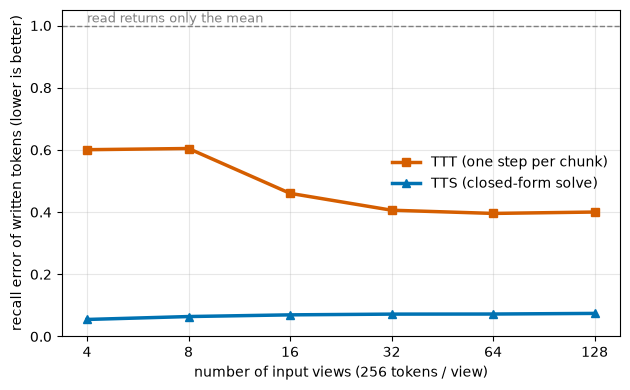

In [3]:
res = {"TTT (one step per chunk)": [], "TTS (closed-form solve)": []}
for n in VIEWS:
    M = n * TOK_PER_VIEW
    k, v = make_tokens(M, seed=n)
    e_ttt = recall_error(ttt_write(k, v, W0), k, v)
    e_tts = recall_error(tts_write(k, v, W0), k, v)
    res["TTT (one step per chunk)"].append(e_ttt); res["TTS (closed-form solve)"].append(e_tts)
    print(f"{n:4d} views ({M:6d} tokens):  recall error  TTT {e_ttt:.3f}   TTS {e_tts:.3f}")

plt.figure(figsize=(6.4, 4))
for (lab, ys), col, mk in zip(res.items(), ["#D55E00", "#0072B2"], ["s", "^"]):
    plt.plot(VIEWS, ys, marker=mk, color=col, lw=2.5, label=lab)
plt.xscale("log", base=2); plt.xticks(VIEWS, VIEWS); plt.ylim(0, 1.05)
plt.axhline(1, ls="--", c="gray", lw=1); plt.text(4, 1.01, "read returns only the mean", fontsize=9, color="gray")
plt.xlabel("number of input views (256 tokens / view)"); plt.ylabel("recall error of written tokens (lower is better)")
plt.legend(frameon=False); plt.grid(alpha=.3); plt.tight_layout(); plt.show()

## 2. Does the order of the inputs matter?

The TTS state consists of weighted sums over tokens, so any order of the inputs gives the same memory (up to floating-point
rounding). TTT writes chunk by chunk, each step starting from the weights the previous chunk left, so the order changes the
memory.

In [4]:
k, v = make_tokens(32 * TOK_PER_VIEW, seed=32)
perm = torch.randperm(len(k), device=k.device)
q = k[:512]
for name, write in [("TTT", lambda kk, vv: ttt_write(kk, vv, W0)), ("TTS", lambda kk, vv: tts_write(kk, vv, W0))]:
    r1, r2 = write(k, v)(q), write(k[perm], v[perm])(q)
    rel = ((r1 - r2).norm() / r1.norm()).item()
    print(f"{name}: relative change of the reads after shuffling the 32 input views: {rel:.2e}")

TTT: relative change of the reads after shuffling the 32 input views: 2.52e-02
TTS: relative change of the reads after shuffling the 32 input views: 5.03e-07


## 3. Where does a read come from?

For a written key $k_m$ we measure, by automatic differentiation, how strongly each written value $v_n$ influences the read:
$s_{mn}=\|\partial\,\mathrm{read}(k_m)/\partial v_n\|_F$ (this is how Fig. 3 of the paper is computed). We show it relative
to the token's own value $s_{mm}$. A memory without interference returns mainly $v_m$ itself.

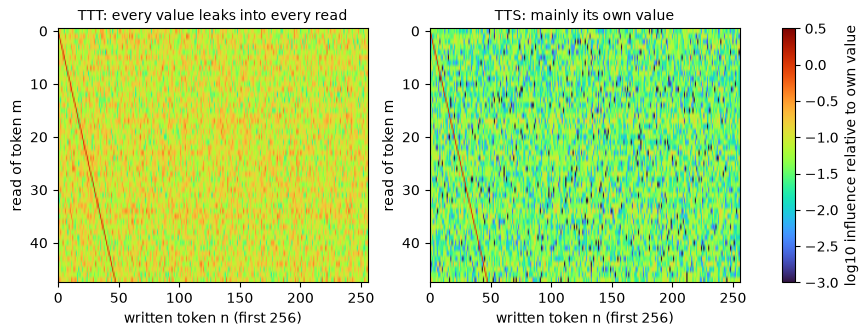

TTT: share of the read's sensitivity that comes from its own value: 4.50%
TTS: share of the read's sensitivity that comes from its own value: 23.50%


In [5]:
M, Q = 4 * TOK_PER_VIEW, 48
k, v = make_tokens(M, seed=4)
def influence(write, n_probe=4):
    vv = v.clone().requires_grad_(True)
    reads = write(k, vv)(k[:Q])                         # Q x d
    S = torch.zeros(Q, M, device=k.device)
    for m in range(Q):
        for _ in range(n_probe):                        # random projections estimate the Frobenius norm of the Jacobian
            z = torch.randn(d, device=k.device)
            g, = torch.autograd.grad(reads[m] @ z, vv, retain_graph=True)
            S[m] += (g ** 2).sum(1) / n_probe
    return S.sqrt()
St = influence(lambda kk, vv: ttt_write(kk, vv, W0))
Ss = influence(lambda kk, vv: tts_write(kk, vv, W0))
fig, ax = plt.subplots(1, 2, figsize=(11, 3.3))
for a_, Sm, t in [(ax[0], St, "TTT: every value leaks into every read"), (ax[1], Ss, "TTS: mainly its own value")]:
    rel = Sm / Sm[torch.arange(Q), torch.arange(Q)].unsqueeze(1)
    im = a_.imshow(torch.log10(rel[:, :256].clamp_min(1e-3)).cpu(), cmap="turbo", vmin=-3, vmax=0.5, aspect="auto")
    a_.set_title(t, fontsize=10); a_.set_xlabel("written token n (first 256)"); a_.set_ylabel("read of token m")
fig.colorbar(im, ax=ax, label="log10 influence relative to own value"); plt.show()
for name, Sm in [("TTT", St), ("TTS", Ss)]:
    own = Sm[torch.arange(Q), torch.arange(Q)] ** 2
    print(f"{name}: share of the read's sensitivity that comes from its own value: {(own / (Sm ** 2).sum(1)).mean().item():.2%}")

## 4. Speed of a training step at the size of the real model

Feature dimension $h=1536$ and value dimension $d=768$ as in our 24-layer model, 256 tokens per view. We time what a
training step does in one layer: **write** all input tokens, **read** 1024 query tokens, and **back-propagate** a loss on the
reads to the keys and values. TTT takes one Muon step per chunk of 2048 tokens, so its backward pass runs through every
chunk's Newton-Schulz iterations in sequence; TTS writes with one large matrix product and one linear solve, and both have
cheap gradients.

What to expect: with few views TTS pays a fixed cost for the $h	imes h$ solve, so a single chunk of TTT is cheaper; the
TTT cost grows with every chunk and its backward pass is sequential, so TTS overtakes it as the number of views grows. In the
full 24-layer model (bf16, our closed-form backward, 32 views at $128^2$) the measured training step is about 1.9x faster
than the FSM-style memory (Table 1 of the paper).

   8 views (  2048 tokens):  forward  TTT    1.3 ms  TTS    8.1 ms   |   forward+backward  TTT    3.8 ms  TTS   11.4 ms  (0.3x)


  32 views (  8192 tokens):  forward  TTT    4.7 ms  TTS   10.0 ms   |   forward+backward  TTT   14.7 ms  TTS   16.8 ms  (0.9x)


 128 views ( 32768 tokens):  forward  TTT   18.3 ms  TTS   17.4 ms   |   forward+backward  TTT   65.3 ms  TTS   38.3 ms  (1.7x)


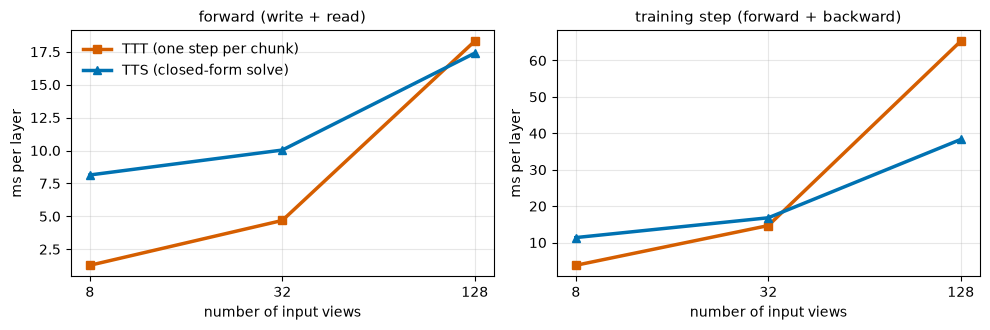

In [6]:
def bench(fn, reps=5):
    fn()                                                   # warm-up
    if dev == "cuda": torch.cuda.synchronize()
    t0 = time.perf_counter()
    for _ in range(reps): fn()
    if dev == "cuda": torch.cuda.synchronize()
    return (time.perf_counter() - t0) / reps * 1000

hB, dB = 1536, 768
W0B = torch.randn(dB, hB, device=dev) * 0.02
qB = torch.nn.functional.normalize(torch.randn(1024, hB, device=dev), dim=1)
def train_step(write, kB, vB):
    k_ = kB.clone().requires_grad_(True); v_ = vB.clone().requires_grad_(True)
    loss = write(k_, v_, W0B)(qB).square().mean()
    loss.backward()
rows = []
for n in [8, 32, 128]:
    M = n * TOK_PER_VIEW
    kB = torch.nn.functional.normalize(torch.randn(M, hB, device=dev), dim=1)
    vB = torch.randn(M, dB, device=dev)
    t_fw = (bench(lambda: ttt_write(kB, vB, W0B)(qB)), bench(lambda: tts_write(kB, vB, W0B)(qB)))
    t_tr = (bench(lambda: train_step(ttt_write, kB, vB)), bench(lambda: train_step(tts_write, kB, vB)))
    rows.append((n, M) + t_fw + t_tr)
    print(f"{n:4d} views ({M:6d} tokens):  forward  TTT {t_fw[0]:6.1f} ms  TTS {t_fw[1]:6.1f} ms   |   "
          f"forward+backward  TTT {t_tr[0]:6.1f} ms  TTS {t_tr[1]:6.1f} ms  ({t_tr[0] / t_tr[1]:.1f}x)")
fig, ax = plt.subplots(1, 2, figsize=(10, 3.4), sharey=False)
xs = [r[0] for r in rows]
for a_, i, ttl in [(ax[0], 2, "forward (write + read)"), (ax[1], 4, "training step (forward + backward)")]:
    a_.plot(xs, [r[i] for r in rows], "s-", c="#D55E00", lw=2.5, label="TTT (one step per chunk)")
    a_.plot(xs, [r[i + 1] for r in rows], "^-", c="#0072B2", lw=2.5, label="TTS (closed-form solve)")
    a_.set_xscale("log", base=2); a_.set_xticks(xs, xs); a_.set_xlabel("number of input views"); a_.set_ylabel("ms per layer")
    a_.set_title(ttl, fontsize=11); a_.grid(alpha=.3)
ax[0].legend(frameon=False); plt.tight_layout(); plt.show()

## Takeaway

One optimization step per chunk does not store what it is shown: as more views are written, every read becomes a blend of
all values, and the result depends on the order of the inputs. Solving the same fit exactly keeps the reads sharp, is
independent of the order, needs only five weighted sums of fixed size, and gets cheaper relative to TTT as more views are
written, because the sums over all tokens are one large matrix product instead of a sequence of chunk-by-chunk steps. In the full model (see `fit_one_scene.ipynb` and
the paper) this is what lets quality keep improving with more input views and higher resolution.